# Notebook 07: Regularización y Cuaderno de Experimentos

**Objetivo:** Evaluar técnicas de regularización (Dropout, weight decay L2 y early stopping) sobre el MLP de riesgo crediticio, comparar las curvas de aprendizaje frente al modelo base y registrar un cuaderno de experimentos controlados (Secciones 12 y 13 de la plantilla).

In [1]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Clonar el repositorio para acceder a la carpeta src (si no existe)
if not os.path.exists('redes-neuronales-riesgo-crediticio'):
    !git clone https://github.com/JuanCardona2203/redes-neuronales-riesgo-crediticio.git

for repo_path in ['/content/redes-neuronales-riesgo-crediticio', '..']:
    if repo_path not in sys.path:
        sys.path.append(repo_path)

from src.model import CreditRiskMLP

In [2]:
# Semilla fija para reproducibilidad (Sección 10)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Carga de los datos escalados generados en 02_quality.ipynb
X_train = pd.read_csv('data/processed/X_train_scaled.csv').values
y_train = pd.read_csv('data/processed/y_train.csv').values.ravel()

# División interna Train/Validación (80/20) estratificada
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)

print(f"Entrenamiento: {X_tr_t.shape[0]} muestras | Validación: {X_val_t.shape[0]} muestras")

Entrenamiento: 20848 muestras | Validación: 5212 muestras


## Modelo con regularización

Se define una variante del MLP que añade **Dropout** entre las capas ocultas. El **weight decay (L2)** se aplica desde el optimizador Adam y el **early stopping** se controla en el ciclo de entrenamiento.

In [3]:
class CreditRiskMLPReg(nn.Module):
    def __init__(self, input_dim, dropout=0.3):
        super(CreditRiskMLPReg, self).__init__()
        self.hidden1 = nn.Linear(input_dim, 16)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(dropout)
        self.hidden2 = nn.Linear(16, 8)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(dropout)
        self.output = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.drop1(self.relu1(self.hidden1(x)))
        out = self.drop2(self.relu2(self.hidden2(out)))
        out = self.sigmoid(self.output(out))
        return out

In [4]:
# Función de entrenamiento reutilizable con early stopping opcional
def entrenar(model, weight_decay=0.0, epochs=50, batch_size=32, patience=None):
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=weight_decay)
    train_ds = torch.utils.data.TensorDataset(X_tr_t, y_tr_t)
    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    history = {'train_loss': [], 'val_loss': []}
    best_val, best_state, wait = float('inf'), None, 0

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * xb.size(0)
        train_loss = running / len(train_ds)

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val_t), y_val_t).item()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Early stopping: detener si la validación no mejora durante 'patience' épocas
        if patience is not None:
            if val_loss < best_val:
                best_val, best_state, wait = val_loss, model.state_dict(), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping en época {epoch+1} (val_loss={val_loss:.4f})")
                    model.load_state_dict(best_state)
                    break
    return history

In [5]:
# Modelo base (sin regularización) vs modelo regularizado (Dropout + L2)
torch.manual_seed(SEED)
model_base = CreditRiskMLP(input_dim=6)
hist_base = entrenar(model_base, weight_decay=0.0, epochs=50)

torch.manual_seed(SEED)
model_reg = CreditRiskMLPReg(input_dim=6, dropout=0.3)
hist_reg = entrenar(model_reg, weight_decay=1e-4, epochs=50)

print(f"Base  -> val_loss final: {hist_base['val_loss'][-1]:.4f}")
print(f"Regul -> val_loss final: {hist_reg['val_loss'][-1]:.4f}")

Base  -> val_loss final: 0.3593
Regul -> val_loss final: 0.3690


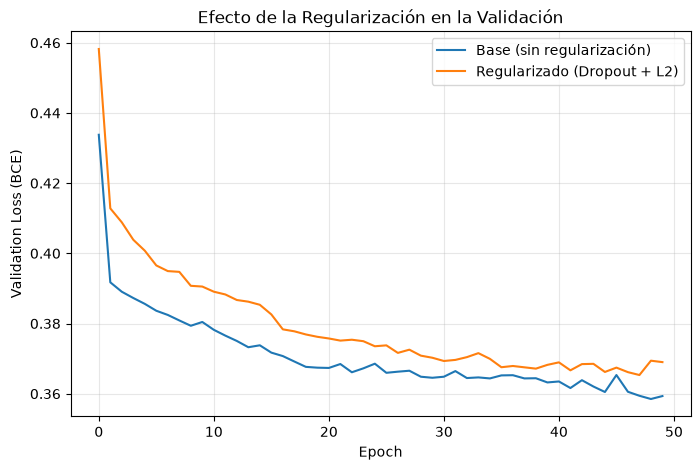

In [6]:
# Comparación de curvas de validación (Sección 12)
plt.figure(figsize=(8, 5))
plt.plot(hist_base['val_loss'], label='Base (sin regularización)')
plt.plot(hist_reg['val_loss'], label='Regularizado (Dropout + L2)')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss (BCE)')
plt.title('Efecto de la Regularización en la Validación')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Cuaderno de experimentos (Sección 13)

Se ejecutan experimentos controlados variando un factor a la vez (misma semilla y mismo conjunto de validación). La métrica de comparación es la pérdida de validación (BCE) final.

In [7]:
def val_loss_final(model, **kwargs):
    torch.manual_seed(SEED)
    h = entrenar(model, **kwargs)
    return h['val_loss'][-1]

experimentos = []

# EXP-01: Baseline
experimentos.append(('EXP-01', 'Baseline MLP (6-16-8-1)', val_loss_final(CreditRiskMLP(6))))
# EXP-02: Dropout 0.3
experimentos.append(('EXP-02', 'Dropout 0.3', val_loss_final(CreditRiskMLPReg(6, dropout=0.3))))
# EXP-03: Dropout 0.5
experimentos.append(('EXP-03', 'Dropout 0.5', val_loss_final(CreditRiskMLPReg(6, dropout=0.5))))
# EXP-04: Weight decay 1e-4
experimentos.append(('EXP-04', 'Weight decay 1e-4', val_loss_final(CreditRiskMLP(6), weight_decay=1e-4)))
# EXP-05: Weight decay 1e-3
experimentos.append(('EXP-05', 'Weight decay 1e-3', val_loss_final(CreditRiskMLP(6), weight_decay=1e-3)))
# EXP-06: Dropout 0.3 + Weight decay 1e-4
experimentos.append(('EXP-06', 'Dropout 0.3 + WD 1e-4', val_loss_final(CreditRiskMLPReg(6, dropout=0.3), weight_decay=1e-4)))
# EXP-07: Batch size 16
experimentos.append(('EXP-07', 'Batch size 16', val_loss_final(CreditRiskMLP(6), batch_size=16)))
# EXP-08: Early stopping (patience=5)
experimentos.append(('EXP-08', 'Early stopping (patience=5)', val_loss_final(CreditRiskMLP(6), patience=5)))

tabla = pd.DataFrame(experimentos, columns=['ID', 'Cambio', 'Val Loss (BCE)'])
tabla = tabla.sort_values('Val Loss (BCE)').reset_index(drop=True)
tabla

,ID,Cambio,Val Loss (BCE)
0,EXP-01,Baseline MLP (6-16-8-1),0.358264
1,EXP-07,Batch size 16,0.360379
2,EXP-08,Early stopping (patience=5),0.361892
3,EXP-02,Dropout 0.3,0.362405
4,EXP-06,Dropout 0.3 + WD 1e-4,0.362572
5,EXP-04,Weight decay 1e-4,0.368420
6,EXP-05,Weight decay 1e-3,0.369674
7,EXP-03,Dropout 0.5,0.384090


In [8]:
# Guardar la tabla de experimentos como evidencia (Sección 13)
os.makedirs('reports', exist_ok=True)
tabla.to_csv('reports/experimentos.csv', index=False)
print('Mejor configuración:')
print(tabla.iloc[0].to_string())

Mejor configuración:
ID                                 EXP-01
Cambio            Baseline MLP (6-16-8-1)
Val Loss (BCE)                   0.358264
